In [1]:
import numpy as np


def anna_find_all_stable(malechoice, femalechoice, n):
    # Output list with all matchings
    res = []
    # Initialization
    unchanged = [True] * n
    marriage = [0] * n
    malecounter = [0] * n
    # Female choice transformation

    fc = np.zeros((n, n), dtype=int)
    for i in range(0, n):
        for j in range(0, n):
            fc[i][femalechoice[i][j]] = j
        fc[i][0] = n
        malecounter[i] = 0
        marriage[i] = 0

    def get_marriage(marriage):
        malematches = [0] * (n)
        for j in range(0, n):
            malematches[marriage[j] - 1] = j
        return(malematches)

    def print_marriage(marriage):
        malematches = [0] * (n)
        for j in range(0, n):
            malematches[marriage[j] - 1] = j
        print(*malematches)

    def proposal(i, malec, marriage, c):
        if i < 0:
            success = True
        elif (i == 0) or malec[i] == (n - 1) or not (unchanged[i]):  # n not (n+1), as we have n equals 5
            success = False
        else:
            c += 1
            j = malec[i]
            malec[i] = j + 1
            success = refusal(i, malechoice[i][j], malec, marriage, c)
        return success

    def refusal(i, j, malec, marriage, c):
        if fc[j][abs(marriage[j])] > fc[j][i]:
            k = marriage[j]
            marriage[j] = i
            success = proposal(k, malec, marriage, c)
        else:
            success = proposal(i, malec, marriage, c)
        return success

    def breakmariage(malecounter, marriage, i, n, count):
        malecounter_ori = malecounter.copy()
        marriage_ori = marriage.copy()
        marriage[malechoice[i][malecounter[i] - 1]] = -i
        success = proposal(i, malecounter, marriage, count)

        if not (success):
            unchanged[i] = False
            malecounter_ref = malecounter_ori.copy()
            marriage_ref = marriage_ori.copy()
            malecounter = malecounter_ref
            marriage = marriage_ref
            return malecounter, marriage

        #print_marriage(marriage)  # marriage[i] means the woman who is married to i man
        new_marriage = get_marriage(marriage)  # convert into female solution
        res.append(new_marriage)
        # establish the relationships between the original and the obtained stable matching

        for j in range(i, n):
            # if i==2 and j==2:
            #     print("This is it")
            malecounter, marriage = breakmariage(malecounter, marriage, j, n, count)

        for j in range((i + 1), n):
            unchanged[j] = True
        # return malecounter_ori, abs(marriage_ori)
        return malecounter_ori, marriage_ori

    count = 0
    for i in range(0, n):
        proposal(i, malecounter, marriage, count)
    #print_marriage(marriage)

    new_marriage = get_marriage(marriage)  # convert into female solution
    res.append(new_marriage)
    # establish the relationships between the original and the obtained stable matching

    M_optimal_marriage = marriage.copy()
    M_optimal_counter = malecounter.copy()
    for i in range(0, n):
        breakmariage(M_optimal_counter.copy(), M_optimal_marriage.copy(), i, n, count)
    return res


In [2]:
import numpy as np


def find_all_stable(malechoice, femalechoice, n):
    # Output list with all matchings
    res = []
    # Initialization
    unchanged = [True] * n
    marriage = [0] * n
    malecounter = [0] * n
    # Female choice transformation

    fc = np.zeros((n, n), dtype=int)
    for i in range(1, n):
        for j in range(0, n - 1):
            fc[i][femalechoice[i][j]] = j
        fc[i][0] = n
        malecounter[i] = 0
        marriage[i] = 0

    def get_marriage(marriage):
        malematches = [0] * (n - 1)
        for j in range(1, n):
            malematches[marriage[j] - 1] = j
        return(malematches)

    def print_marriage(marriage):
        malematches = [0] * (n - 1)
        for j in range(1, n):
            malematches[marriage[j] - 1] = j
        print(*malematches)

    def proposal(i, malec, marriage, c):
        if i < 0:
            success = True
        elif (i == 0) or malec[i] == (n - 1) or not (unchanged[i]):  # n not (n+1), as we have n equals 5
            success = False
        else:
            c += 1
            j = malec[i]
            malec[i] = j + 1
            success = refusal(i, malechoice[i][j], malec, marriage, c)
        return success

    def refusal(i, j, malec, marriage, c):
        if fc[j][abs(marriage[j])] > fc[j][i]:
            k = marriage[j]
            marriage[j] = i
            success = proposal(k, malec, marriage, c)
        else:
            success = proposal(i, malec, marriage, c)
        return success

    def breakmariage(malecounter, marriage, i, n, count):
        malecounter_ori = malecounter.copy()
        marriage_ori = marriage.copy()
        marriage[malechoice[i][malecounter[i] - 1]] = -i
        success = proposal(i, malecounter, marriage, count)

        if not (success):
            unchanged[i] = False
            malecounter_ref = malecounter_ori.copy()
            marriage_ref = marriage_ori.copy()
            malecounter = malecounter_ref
            marriage = marriage_ref
            return malecounter, marriage

        #print_marriage(marriage)  # marriage[i] means the woman who is married to i man
        new_marriage = get_marriage(marriage)  # convert into female solution
        res.append(new_marriage)
        # establish the relationships between the original and the obtained stable matching

        for j in range(i, n):
            # if i==2 and j==2:
            #     print("This is it")
            malecounter, marriage = breakmariage(malecounter, marriage, j, n, count)

        for j in range((i + 1), n):
            unchanged[j] = True
        # return malecounter_ori, abs(marriage_ori)
        return malecounter_ori, marriage_ori

    count = 0
    for i in range(1, n):
        proposal(i, malecounter, marriage, count)
    #print_marriage(marriage)

    new_marriage = get_marriage(marriage)  # convert into female solution
    res.append(new_marriage)
    # establish the relationships between the original and the obtained stable matching

    M_optimal_marriage = marriage.copy()
    M_optimal_counter = malecounter.copy()
    for i in range(1, n - 1):
        breakmariage(M_optimal_counter.copy(), M_optimal_marriage.copy(), i, n, count)
    return res


In [4]:
import pandas as pd
import json
from collections import defaultdict

df = pd.read_csv('mallows_MD_accomplice.csv')

stable_matchings_count = defaultdict(list)
stable_matchings_count_anna = defaultdict(list)
stable_lst = []
stable_lst_anna = []

for i in range(len(df)):
    
    mpref = json.loads(df.loc[i, 'mpref'])
    wpref = json.loads(df.loc[i, 'wpref'])

    m_pref = [[int(x)-1 for x in sublist] for sublist in mpref]
    w_pref = [[int(x)-1 for x in sublist] for sublist in wpref]
    
    res1 = anna_find_all_stable(m_pref, w_pref, len(m_pref))
    res2 = find_all_stable([[]] + mpref, [[]] + wpref, len(mpref) + 1)
    #print(stable_matchings)
    num_stable_matchings_anna = len(res1)
    num_stable_matchings = len(res2)
    stable_lst.append(num_stable_matchings)
    stable_lst_anna.append(num_stable_matchings_anna)
    
    dimension = df.loc[i, 'phi_m']
    proportion = df.loc[i, 'phi_w']
    
    stable_matchings_count[(dimension, proportion)].append(num_stable_matchings)
    stable_matchings_count_anna[(dimension, proportion)].append(num_stable_matchings_anna)

df['number_of_stable_matchings'] = stable_lst
df['number_of_stable_matchings_anna'] = stable_lst_anna

df.to_csv('mallows_MD_test.csv', index=False)

#averages = {
    #(dimension, proportion): sum(counts) / len(counts)
    #for (dimension, proportion), counts in stable_matchings_count.items()}

#for (dimension, proportion), avg in sorted(averages.items()):
    #print(f"dimension: {dimension}, proportion: {proportion} -> Average Stable Matchings: {avg:.2f}")


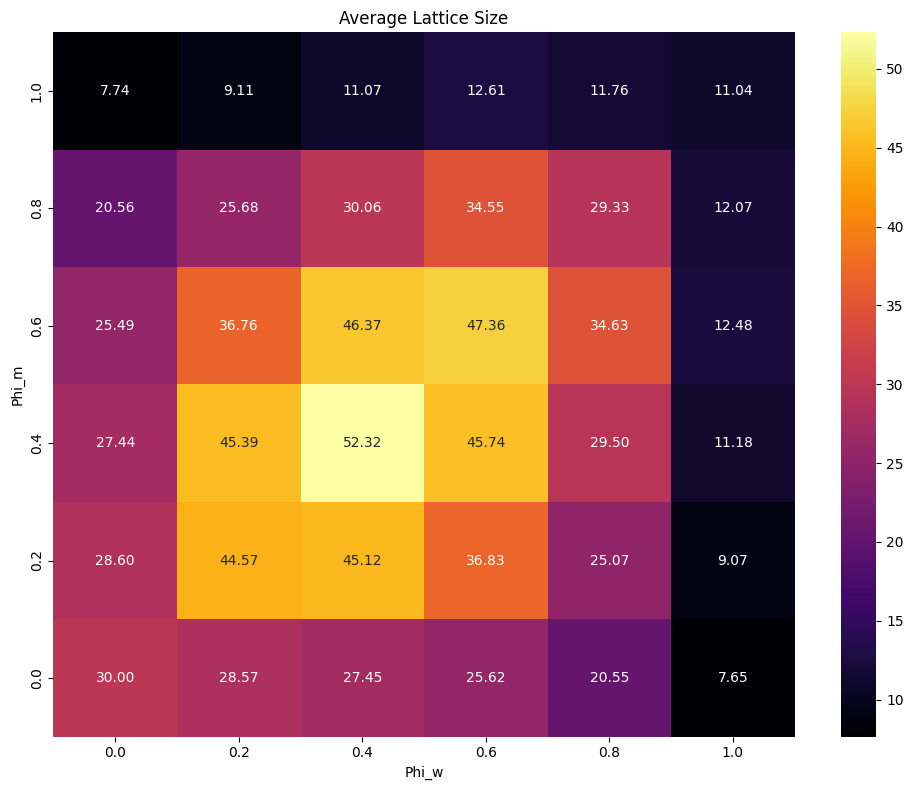

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
# Load the CSV with stability counts
df = pd.read_csv("mallows_MD_test.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["phi_m", "phi_w"])["number_of_stable_matchings"]
    .mean()
    .reset_index()
)
# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="phi_m", columns="phi_w", values="number_of_stable_matchings")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Average Lattice Size")
plt.xlabel("Phi_w")
plt.ylabel("Phi_m")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


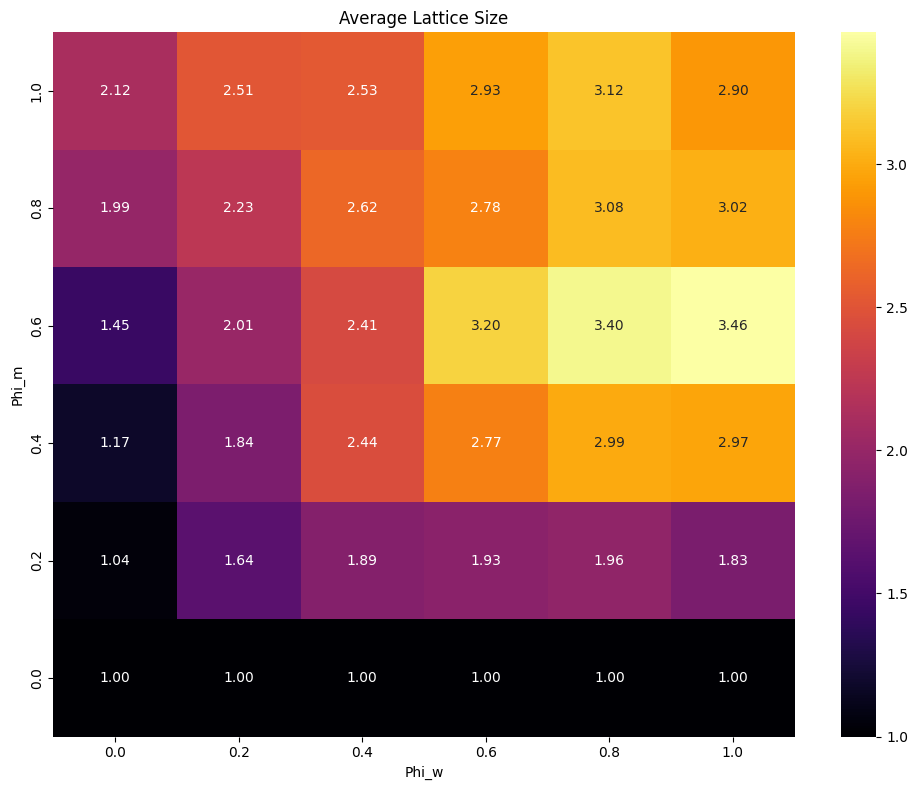

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
# Load the CSV with stability counts
df = pd.read_csv("mallows_MD_test.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["phi_m", "phi_w"])["number_of_stable_matchings_anna"]
    .mean()
    .reset_index()
)
# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="phi_m", columns="phi_w", values="number_of_stable_matchings_anna")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Average Lattice Size")
plt.xlabel("Phi_w")
plt.ylabel("Phi_m")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()
